# Salidas del equipo

## Librerías

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from math import pi

## Ver qué jugadores no continuan en el club

In [7]:
# Cargar los DataFrames desde los archivos
ruta_data = Path.cwd().parent.parent / "data" / "udlaspalmas"

df_plantilla = pd.read_csv(ruta_data / "df_plantilla_2627.csv")
df_individual = pd.read_excel(ruta_data / "Individual Las Palmas 2526.xlsx")
df_equipo_total = pd.read_excel(ruta_data / "Team Stats Las Palmas.xlsx")

In [5]:
# Diccionario de mapeo: 'Nombre Métrica' : 'Nombre Plantilla'
diccionario_nombres = {
    'Mika Mármol': 'Mika Mármol',
    'Kirian Rodríguez': 'Kirian Rodríguez',
    'E. Loiodice': 'Enzo Loiodice',
    'N. Benedetti': 'Nicolás Benedetti',
    'Manu Fuster': 'Manu Fuster',
    'Marvin Park': 'Marvin Park',
    'José Antonio Caro': 'José Antonio Caro',
    'Pejiño': 'Pejiño',
    'Cristian Gutiérrez': 'Cristian Gutiérrez',
    'Álex Suárez': 'Álex Suárez',
    'D. Horkaš': 'Dinko Horkas',
    'Sergio Barcia': 'Sergio Barcia',
    'Iván Gil': 'Iván Gil',
    'Jonathan Viera': 'Jonathan Viera',
    'T. Miyashiro': 'Taisei Miyashiro',
    'Jesé Rodríguez': 'Jesé',
    'Iker Bravo': 'Iker Bravo',
    'Enrique Clemente': 'Enrique Clemente',
    'Ale García': 'Ale García',
    'Sandro Ramírez': 'Sandro Ramírez',
    'Viti Rozada': 'Viti Rozada',
    'J. Recoba': 'Jeremía Recoba',
    'Juanma Herzog': 'Juanma Herzog',
    'Adrian Suarez': 'Adri Suárez',
    'Estanis Pedrola': 'Estanis Pedrola',
    'Iñaki González': 'Iñaki González',
    'L. Amatucci': 'Lorenzo Amatucci'
}

In [8]:
# Añadir una columna al DF individual con el nombre unificado
df_individual['Jugador_Unificado'] = df_individual['Player'].map(diccionario_nombres)

# Extraer la lista de los jugadores que SÍ tienen contrato para la 26/27
jugadores_que_se_quedan = df_plantilla['Jugador'].tolist()

# Quedarse con los jugadores cuyo nombre unificado NO está en la plantilla 26/27
df_bajas = df_individual[~df_individual['Jugador_Unificado'].isin(jugadores_que_se_quedan)].copy()

# Limpieza final de la estructura
df_bajas = df_bajas.reset_index(drop=True)

print(f"Total de bajas confirmadas: {len(df_bajas)}")

Total de bajas confirmadas: 8


In [10]:
df_bajas['Player']

0        Mika Mármol
1       N. Benedetti
2             Pejiño
3      Sergio Barcia
4     Jonathan Viera
5         Iker Bravo
6    Estanis Pedrola
7        L. Amatucci
Name: Player, dtype: object

## ¿Qué vacío dejan?

In [12]:
# 1Definir las métricas clave para el estilo de Las Palmas
metricas_absolutas = ['Minutes played', 'Goals', 'xG', 'Assists', 'xA']
metricas_p90 = [
    'Progressive runs per 90', 
    'Passes to final third per 90', 
    'Interceptions per 90', 
    'Defensive duels per 90'
]

In [13]:
# Función para convertir P90 a Volumen Total
def calcular_volumen_total(df, absolutas, p90):
    df_calc = df.copy()
    # Rellenar NaNs con 0 por seguridad
    df_calc = df_calc.fillna(0) 
    
    # Transformar métricas P90 a Volumen Total: (Métrica / 90) * Minutos Jugados
    for col in p90:
        nombre_nueva_col = col.replace(' per 90', ' (Total)')
        df_calc[nombre_nueva_col] = (df_calc[col] * df_calc['Minutes played']) / 90
        
    # Agrupar todas las columnas de volumen
    cols_volumen = absolutas + [col.replace(' per 90', ' (Total)') for col in p90]
    return df_calc[cols_volumen].sum()

In [14]:
# 3. Calcular los totales
# Total del equipo (usamos df_individual completo para ser exactos con la suma de la plantilla)
volumen_equipo = calcular_volumen_total(df_individual, metricas_absolutas, metricas_p90)

# Total de los que se van (df_bajas)
volumen_bajas = calcular_volumen_total(df_bajas, metricas_absolutas, metricas_p90)

In [15]:
df_impacto = pd.DataFrame({
    'Total Equipo': volumen_equipo,
    'Pérdida Absoluta (Bajas)': volumen_bajas
})
df_impacto['% Perdido'] = (df_impacto['Pérdida Absoluta (Bajas)'] / df_impacto['Total Equipo']) * 100
df_impacto['% Se Queda'] = 100 - df_impacto['% Perdido']

# Redondear para estética
df_impacto = df_impacto.round(2)
print(df_impacto[['Total Equipo', 'Pérdida Absoluta (Bajas)', '% Perdido']])

                               Total Equipo  Pérdida Absoluta (Bajas)  \
Minutes played                     51006.00                  17056.00   
Goals                                 69.00                     16.00   
xG                                    63.97                     20.78   
Assists                               50.00                     15.00   
xA                                    33.08                     10.81   
Progressive runs (Total)             812.57                    321.24   
Passes to final third (Total)       2389.91                    983.67   
Interceptions (Total)               1662.36                    673.80   
Defensive duels (Total)             2525.74                    995.38   

                               % Perdido  
Minutes played                     33.44  
Goals                              23.19  
xG                                 32.48  
Assists                            30.00  
xA                                 32.68  
Progressive

### Visualizaciones

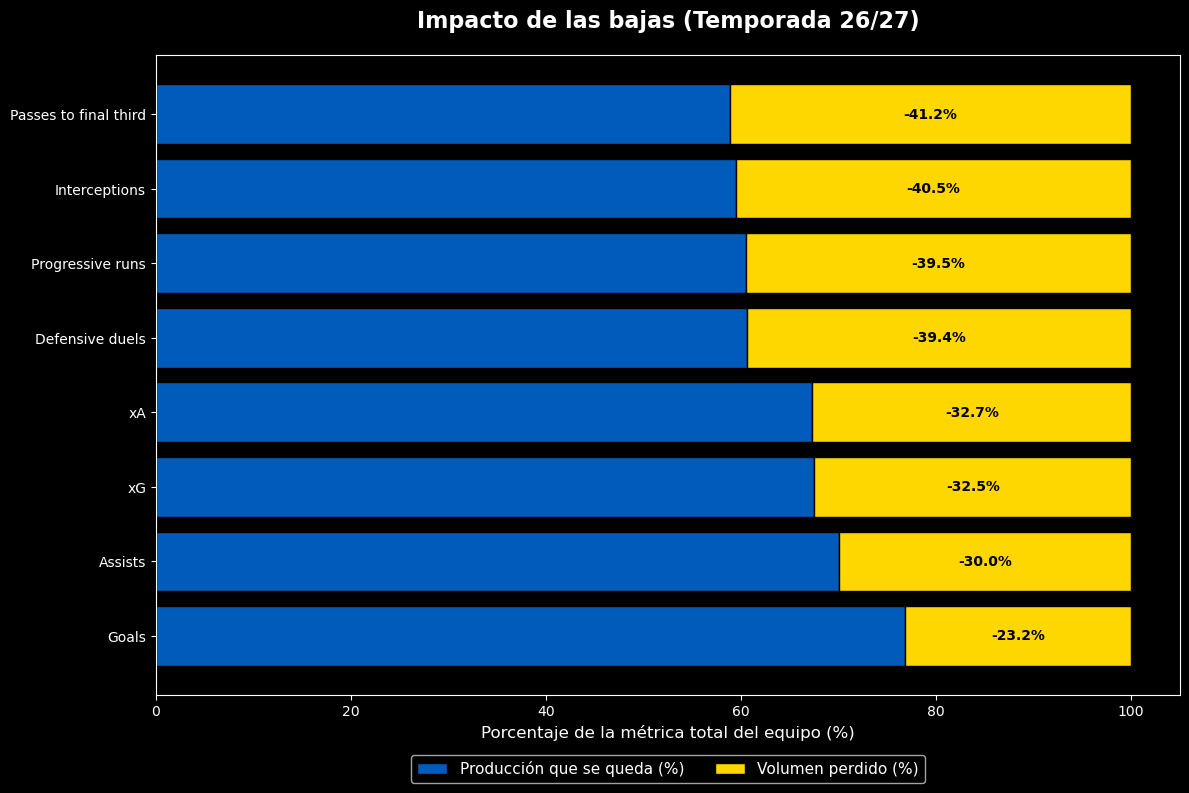

In [16]:
# Gráfico 1
plt.style.use('dark_background')
fig, ax = plt.subplots(figsize=(12, 8))

# Ordenar de mayor a menor pérdida para mayor impacto visual
df_plot = df_impacto.drop('Minutes played').sort_values('% Perdido', ascending=True)

# Variables para el gráfico
etiquetas = df_plot.index.str.replace(' (Total)', '')
perdido = df_plot['% Perdido']
se_queda = df_plot['% Se Queda']

# Colores (Azul UDLP para lo que se queda, Amarillo UDLP para la fuga)
color_queda = '#005BBB' 
color_fuga = '#FFD700'  

# Crear barras apiladas
ax.barh(etiquetas, se_queda, color=color_queda, edgecolor='black', label='Producción que se queda (%)')
ax.barh(etiquetas, perdido, left=se_queda, color=color_fuga, edgecolor='black', label='Volumen perdido (%)')

# Personalización del gráfico
ax.set_title('Impacto de las bajas (Temporada 26/27)', fontsize=16, fontweight='bold', pad=20)
ax.set_xlabel('Porcentaje de la métrica total del equipo (%)', fontsize=12)
ax.legend(loc='lower center', bbox_to_anchor=(0.5, -0.15), ncol=2, fontsize=11)

# Añadir etiquetas de datos en las barras
for i, (q, p) in enumerate(zip(se_queda, perdido)):
    # Etiqueta de pérdida (amarillo)
    if p > 5: # Solo mostrar si es mayor al 5% para que no se superponga
        ax.text(q + p/2, i, f"-{p:.1f}%", ha='center', va='center', color='black', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()

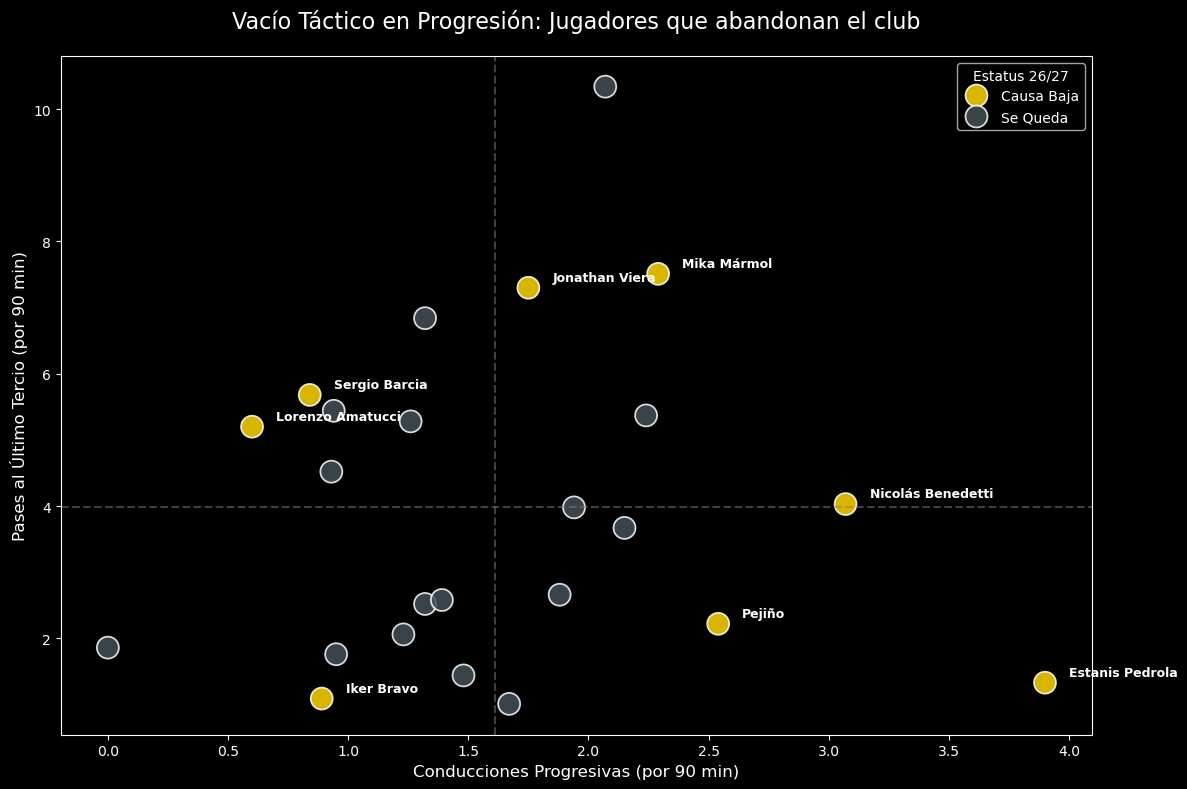

In [17]:
# Crear una etiqueta en el DF general para distinguir estatus
df_individual['Estatus_Plantilla'] = 'Se Queda'
df_individual.loc[df_individual['Jugador_Unificado'].isin(df_bajas['Jugador_Unificado']), 'Estatus_Plantilla'] = 'Causa Baja'

# Configurar el gráfico
plt.style.use('dark_background')
plt.figure(figsize=(12, 8))

# Crear el Scatter Plot
sns.scatterplot(
    data=df_individual, 
    x='Progressive runs per 90', # Conducciones progresivas
    y='Passes to final third per 90', # Pases al último tercio
    hue='Estatus_Plantilla', 
    palette={'Se Queda': '#435058', 'Causa Baja': '#FFD700'}, # Gris para la base, Amarillo UDLP para las bajas
    s=250, # Tamaño de la burbuja
    alpha=0.85, 
    edgecolor='white'
)

# Etiquetar SOLO a los jugadores que se van para no saturar el gráfico
for i in range(df_individual.shape[0]):
    if df_individual['Estatus_Plantilla'].iloc[i] == 'Causa Baja':
        plt.text(
            df_individual['Progressive runs per 90'].iloc[i] + 0.1, 
            df_individual['Passes to final third per 90'].iloc[i] + 0.1, 
            df_individual['Jugador_Unificado'].iloc[i], 
            fontsize=9, color='white', fontweight='bold'
        )

# Personalización
plt.title('Vacío Táctico en Progresión: Jugadores que abandonan el club', fontsize=16, pad=20)
plt.xlabel('Conducciones Progresivas (por 90 min)', fontsize=12)
plt.ylabel('Pases al Último Tercio (por 90 min)', fontsize=12)
plt.axvline(x=df_individual['Progressive runs per 90'].mean(), color='gray', linestyle='--', alpha=0.5)
plt.axhline(y=df_individual['Passes to final third per 90'].mean(), color='gray', linestyle='--', alpha=0.5)
plt.legend(title='Estatus 26/27')

plt.tight_layout()
plt.show()

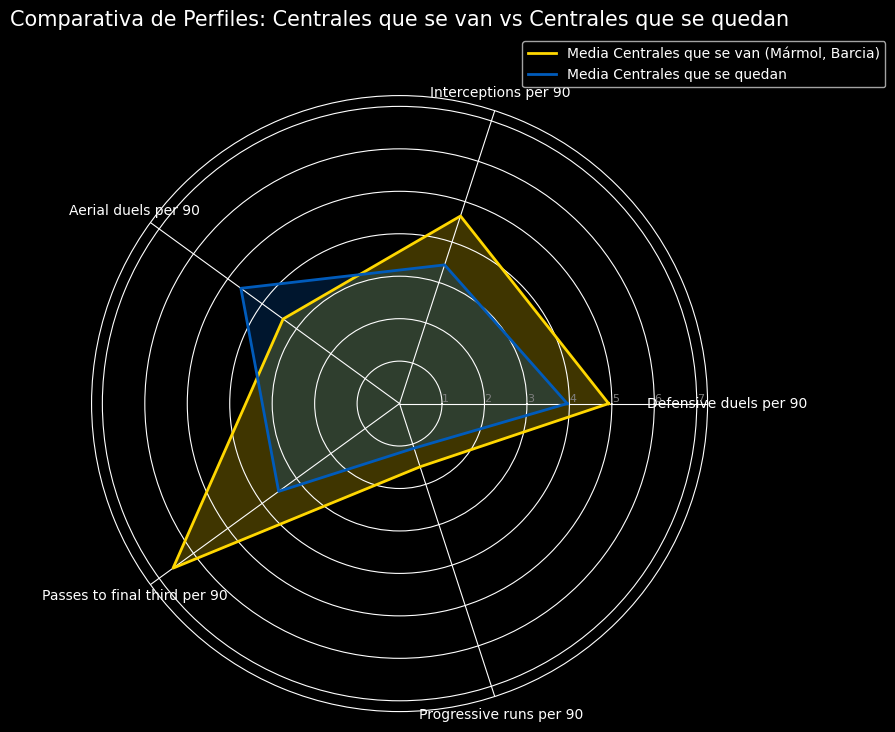

In [19]:
# Definir las métricas clave para un Central en el modelo Las Palmas
metricas_radar = [
    'Defensive duels per 90', 
    'Interceptions per 90', 
    'Aerial duels per 90',
    'Passes to final third per 90',
    'Progressive runs per 90'
]

# 2. Aislar a los centrales que se van vs los que se quedan
# Usamos .loc para evitar warnings y calculamos la media de sus métricas
centrales_baja = df_individual[(df_individual['Position'].str.contains('CB')) & (df_individual['Estatus_Plantilla'] == 'Causa Baja')][metricas_radar].mean()
centrales_quedan = df_individual[(df_individual['Position'].str.contains('CB')) & (df_individual['Estatus_Plantilla'] == 'Se Queda')][metricas_radar].mean()

# Preparar los datos para el Radar (hay que cerrar el polígono repitiendo el primer valor)
valores_baja = centrales_baja.values.flatten().tolist()
valores_baja += valores_baja[:1]

valores_quedan = centrales_quedan.values.flatten().tolist()
valores_quedan += valores_quedan[:1]

angulos = [n / float(len(metricas_radar)) * 2 * pi for n in range(len(metricas_radar))]
angulos += angulos[:1]

# Crear el gráfico de Radar
fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))
plt.style.use('dark_background')

# Configurar ejes
plt.xticks(angulos[:-1], metricas_radar, color='white', size=10)
ax.set_rlabel_position(0)
plt.yticks(color="gray", size=8)
plt.ylim(0, max(max(valores_baja), max(valores_quedan)) * 1.1) # Ajustar límite superior

# Trazar perfil de las Bajas (Amarillo)
ax.plot(angulos, valores_baja, linewidth=2, linestyle='solid', color='#FFD700', label='Media Centrales que se van (Mármol, Barcia)')
ax.fill(angulos, valores_baja, color='#FFD700', alpha=0.25)

# Trazar perfil de los que se Quedan (Azul)
ax.plot(angulos, valores_quedan, linewidth=2, linestyle='solid', color='#005BBB', label='Media Centrales que se quedan')
ax.fill(angulos, valores_quedan, color='#005BBB', alpha=0.25)

plt.title('Comparativa de Perfiles: Centrales que se van vs Centrales que se quedan', size=15, color='white', y=1.1)
plt.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))

plt.show()